## 1. Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns
from PIL import Image

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

print("Libraries imported.")

Libraries imported.


## 2. Load data

In [2]:
df = pd.read_csv('../data/styles.csv', on_bad_lines='skip')

with open('../data/styles.csv', encoding='utf-8') as f:
    raw_lines = sum(1 for _ in f) - 1

print("Rows in file: ", raw_lines)
print("Rows loaded: ", len(df))
print("Malformed rows: ", raw_lines - len(df))

Rows in file:  44446
Rows loaded:  44424
Malformed rows:  22


## 3. First look

In [3]:
print(df.shape)
print(df.dtypes)
df.head(10)

(44424, 10)
id                      int64
gender                    str
masterCategory            str
subCategory               str
articleType               str
baseColour                str
season                    str
year                  float64
usage                     str
productDisplayName        str
dtype: object


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt
5,1855,Men,Apparel,Topwear,Tshirts,Grey,Summer,2011.0,Casual,Inkfruit Mens Chain Reaction T-shirt
6,30805,Men,Apparel,Topwear,Shirts,Green,Summer,2012.0,Ethnic,Fabindia Men Striped Green Shirt
7,26960,Women,Apparel,Topwear,Shirts,Purple,Summer,2012.0,Casual,Jealous 21 Women Purple Shirt
8,29114,Men,Accessories,Socks,Socks,Navy Blue,Summer,2012.0,Casual,Puma Men Pack of 3 Socks
9,30039,Men,Accessories,Watches,Watches,Black,Winter,2016.0,Casual,Skagen Men Black Watch


## 4. Missing values

In [4]:
missing = df.isnull().sum().to_frame('missing')
missing['pct'] = (missing['missing'] / len(df) * 100).round(2)
missing

,missing,pct
id,0,0.00
gender,0,0.00
masterCategory,0,0.00
subCategory,0,0.00
articleType,0,0.00
baseColour,15,0.03
season,21,0.05
year,1,0.00
usage,317,0.71
productDisplayName,7,0.02


## 5. Duplicates 

In [5]:
print("Duplicated Ids: ", df["id"].duplicated().sum())
print("Fully duplicate rows: ", df.duplicated().sum())

Duplicated Ids:  0
Fully duplicate rows:  0


## 6. Product taxonomy

In [6]:
cat_table = (df.groupby(['masterCategory','subCategory'])
             .size().reset_index(name='count')
             .sort_values('count', ascending=False))
cat_table

,masterCategory,subCategory,count
27,Apparel,Topwear,15402
30,Footwear,Shoes,7343
1,Accessories,Bags,3055
21,Apparel,Bottomwear,2694
18,Accessories,Watches,2542
23,Apparel,Innerwear,1808
7,Accessories,Jewellery,1079
4,Accessories,Eyewear,1073
37,Personal Care,Fragrance,1011
29,Footwear,Sandal,963


## 7. Detailed values

In [7]:
print(df['articleType'].value_counts().head(40))
print(df['baseColour'].value_counts())
print(df['usage'].value_counts(dropna=False))
print(df['season'].value_counts(dropna=False))
print(df['gender'].value_counts(dropna=False))

articleType
Tshirts                  7067
Shirts                   3217
Casual Shoes             2845
Watches                  2542
Sports Shoes             2036
Kurtas                   1844
Tops                     1762
Handbags                 1759
Heels                    1323
Sunglasses               1073
Wallets                   936
Flip Flops                914
Sandals                   897
Briefs                    849
Belts                     813
Backpacks                 724
Socks                     686
Formal Shoes              637
Perfume and Body Mist     613
Jeans                     609
Shorts                    547
Trousers                  530
Flats                     500
Bra                       477
Dresses                   464
Sarees                    427
Earrings                  416
Deodorant                 347
Nail Polish               329
Lipstick                  315
Track Pants               304
Clutches                  290
Sweatshirts               28

## 8. Products by Master Category

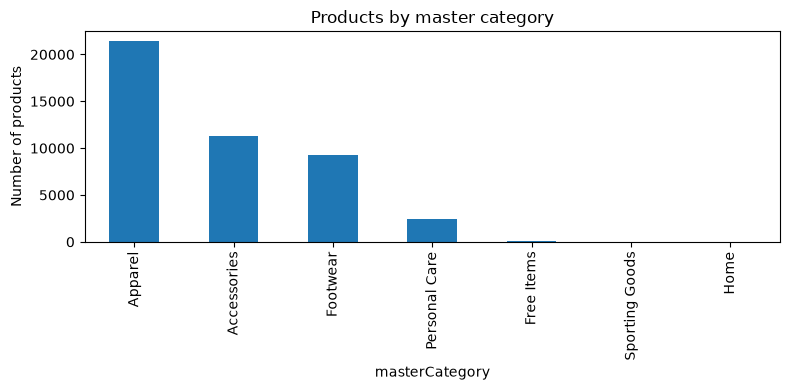

In [8]:
os.makedirs('../documentation', exist_ok=True)

plt.figure(figsize=(8,4))
df['masterCategory'].value_counts().plot(kind='bar')

plt.title('Products by master category')
plt.ylabel('Number of products')
plt.tight_layout()

plt.savefig('../documentation/master_category_counts.png', dpi=150)
plt.show()

## 9. Check if images match csv

In [9]:
img_dir = '../data/images'
img_ids = set(int(f.split('.')[0]) for f in os.listdir(img_dir)
              if f.endswith('.jpg') and f.split('.')[0].isdigit())
csv_ids = set(df['id'])

print('Images on disk:', len(img_ids))
print('Products in CSV:', len(csv_ids))
print('In CSV but no image:', len(csv_ids - img_ids))
print('Image but not in CSV:', len(img_ids - csv_ids))

Images on disk: 44441
Products in CSV: 44424
In CSV but no image: 5
Image but not in CSV: 22


## 10. Searching for pairing labels

In [11]:
print('Columns:', df.columns.tolist())
print('Files in data folder:', os.listdir('../data'))

keywords = ['outfit', 'pair', 'bought', 'match', 'look', 'combo', 'group']
hits = [
    c for c in df.columns
    if any(k in c.lower() for k in keywords)
]
print('Columns hinting at pairing information:', hits)

Columns: ['id', 'gender', 'masterCategory', 'subCategory', 'articleType', 'baseColour', 'season', 'year', 'usage', 'productDisplayName']
Files in data folder: ['images', 'styles.csv']
Columns hinting at pairing information: []


## 10. Looking at real images

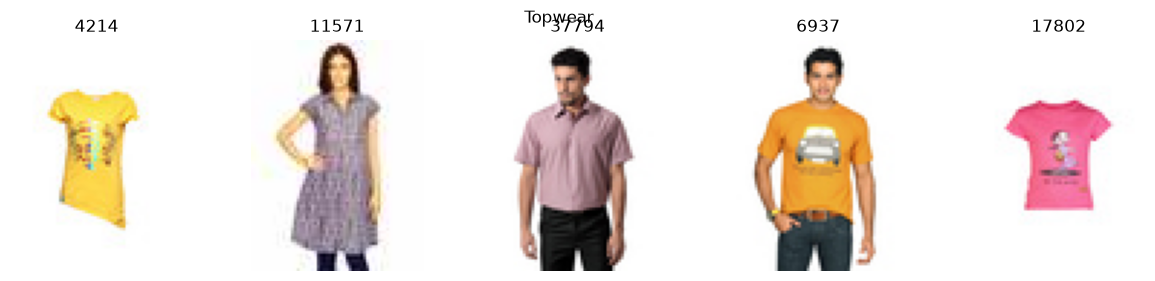

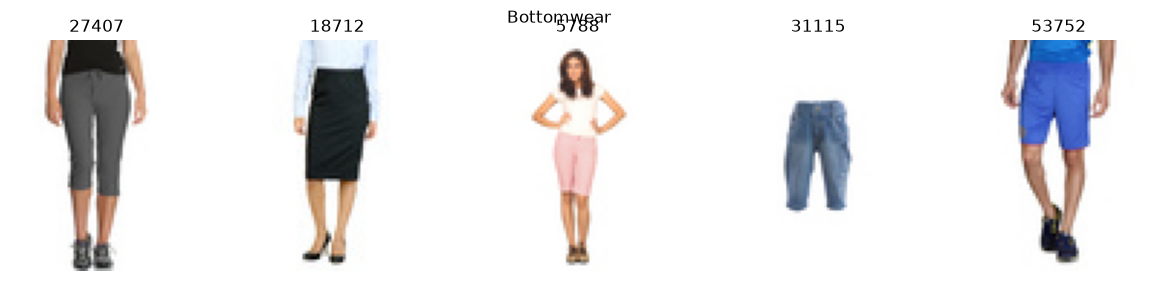

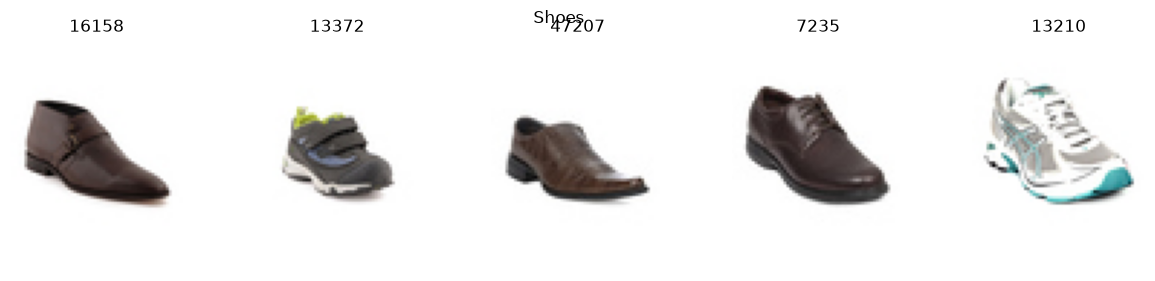

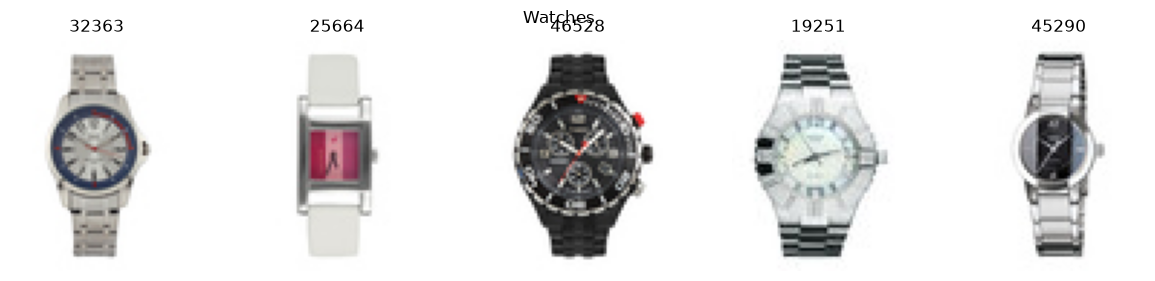

In [12]:
# 11. Sample images
def show_samples(sub, n=5):
    ids = df[df['subCategory'] == sub].sample(n, random_state=1)['id']
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    for ax, i in zip(axes, ids):
        ax.imshow(Image.open(f'../data/images/{i}.jpg'))
        ax.axis('off')
        ax.set_title(str(i))
    plt.suptitle(sub)
    plt.show()

for s in ['Topwear', 'Bottomwear', 'Shoes', 'Watches']:
    show_samples(s)

Image dimensions: (60, 80)
Image format: JPEG
Image mode: RGB


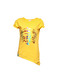

In [13]:
image_path = '../data/images/4214.jpg'

with Image.open(image_path) as img:
    print('Image dimensions:', img.size)
    print('Image format:', img.format)
    print('Image mode:', img.mode)
    display(img)


## 11. Inspecting vague categories

In [14]:
print(df[df['subCategory'] == 'Accessories']['articleType'].value_counts(), '\n')
print(df[df['subCategory'] == 'Bags']['articleType'].value_counts())

articleType
Accessory Gift Set    97
Travel Accessory      15
Messenger Bag         10
Water Bottle           4
Key chain              2
Hair Accessory         1
Name: count, dtype: int64 

articleType
Handbags            1757
Backpacks            722
Clutches             289
Duffel Bag            88
Laptop Bag            81
Mobile Pouch          47
Messenger Bag         34
Waist Pouch           17
Rucksacks             11
Trolley Bag            3
Tablet Sleeve          3
Wallets                2
Travel Accessory       1
Name: count, dtype: int64


## 12. Recommendation universe

In [16]:
keep_master = ['Apparel', 'Footwear', 'Accessories']
outfit_df = df[df['masterCategory'].isin(keep_master)].copy()
print('After keeping 3 master categories:', len(outfit_df))

not_outfit = ['Accessories', 'Innerwear', 'Loungewear and Nightwear', 'Socks']
outfit_df = outfit_df[~outfit_df['subCategory'].isin(not_outfit)]

drop_article_types = ['Laptop Bag', 'Trolley Bag', 'Tablet Sleeve']
outfit_df = outfit_df[~outfit_df['articleType'].isin(drop_article_types)]

sub_counts = outfit_df['subCategory'].value_counts()
tiny = sub_counts[sub_counts < 50].index.tolist()
print('Dropping tiny subcategories:', tiny)
outfit_df = outfit_df[~outfit_df['subCategory'].isin(tiny)]

outfit_df = outfit_df.dropna(subset=['baseColour', 'usage', 'season', 'gender'])
outfit_df = outfit_df[outfit_df['id'].isin(img_ids)]
outfit_df = outfit_df.drop_duplicates('id')

print(len(df), '->', len(outfit_df))

After keeping 3 master categories: 41890
Dropping tiny subcategories: ['Mufflers', 'Shoe Accessories', 'Gloves', 'Water Bottle', 'Umbrellas', 'Sports Accessories', 'Perfumes']
44424 -> 38541
